<a href="https://colab.research.google.com/github/Xquisite-design/enterprise-presales-knowledge-orchestration/blob/main/notebooks/04_RQ2_Knowledge_Routing_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 4 of 5 : RQ2 - Knowledge Routing Agent

Inferential statistics, feature engineering, models and evaluation for predicting the enterprise knowledge repository.
The trained routing model is saved to Drive for RQ3.

**Run first:** `01_Data_Loading_Quality_Cleaning.ipynb` &nbsp;|&nbsp; **Next:** `05_RQ3_Response_Generation_Agent.ipynb`

In [ ]:
###############################################################
# SETUP : MOUNT DRIVE, IMPORTS AND LOAD HANDOFF DATA
###############################################################

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

BASE_DIR = "/content/drive/MyDrive/DataAnalytics_Capstone"
HANDOFF_DIR = f"{BASE_DIR}/handoff"

# Cleaned dataset saved by 01_Data_Loading_Quality_Cleaning.ipynb
df = pd.read_pickle(f"{HANDOFF_DIR}/cleaned_dataset.pkl")

print(df.shape)

# PART-C: RQ2 – Knowledge Routing Agent

## 1. Inferential Statistics (RQ2 specific)

Enterprise Knowledge Repository Distribution


,Count,Percentage
Enterprise Knowledge Required,,
Public Documentation | Architecture Blueprint | Methodology | SME,411,45.67
Public Documentation | Governance Framework | Risk Register | SME,190,21.11
Public Documentation | Commercial Model | Pricing Template | SME,153,17.00
Public Documentation,146,16.22


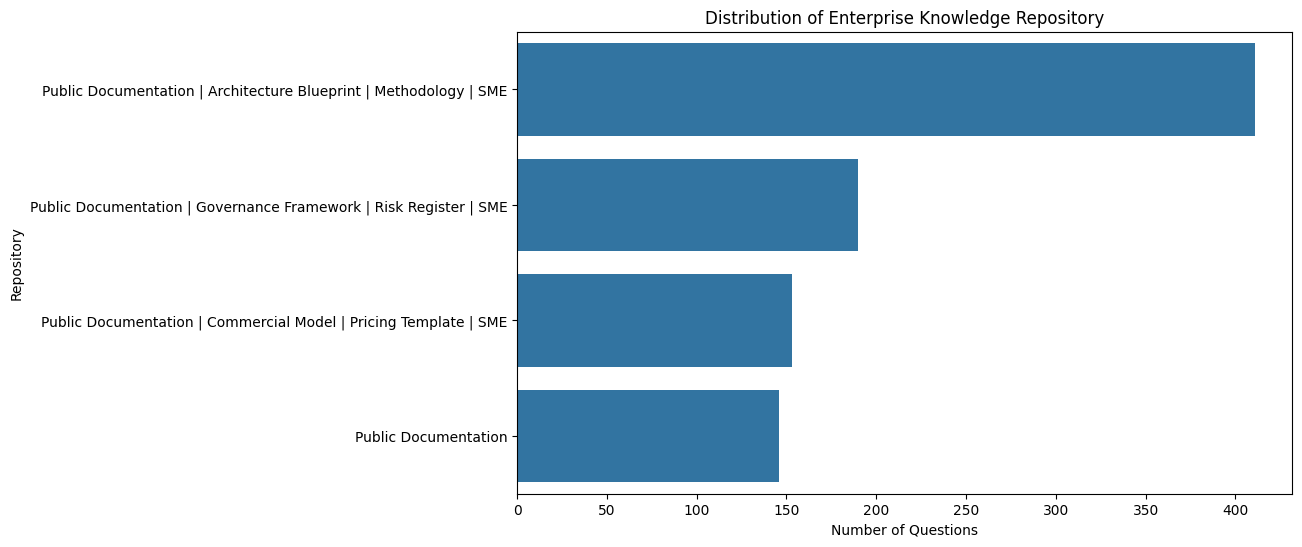

In [33]:
##Lets understand the

###############################################################
# RQ2 : TARGET VARIABLE DISTRIBUTION
###############################################################

print("="*80)
print("Enterprise Knowledge Repository Distribution")
print("="*80)

repo_counts = df["Enterprise Knowledge Required"].value_counts()

repo_percent = round(
    df["Enterprise Knowledge Required"].value_counts(normalize=True)*100,
    2
)

distribution = pd.DataFrame({

    "Count":repo_counts,

    "Percentage":repo_percent

})

display(distribution)

plt.figure(figsize=(10,6))

sns.countplot(

    data=df,

    y="Enterprise Knowledge Required",

    order=repo_counts.index

)

plt.title("Distribution of Enterprise Knowledge Repository")

plt.xlabel("Number of Questions")

plt.ylabel("Repository")

plt.show()

The dataset contains four repository classes representing the enterprise knowledge required to answer a question. Approximately 46% of questions require Architecture Blueprints and Methodologies in addition to public documentation, followed by Governance (21%) and Pricing (17%). Only 16% of questions can be answered using public documentation alone. This indicates that the majority of enterprise presales questions require internal organizational knowledge beyond publicly available information.

Enterprise Knowledge Required,Public Documentation,Public Documentation | Architecture Blueprint | Methodology | SME,Public Documentation | Commercial Model | Pricing Template | SME,Public Documentation | Governance Framework | Risk Register | SME
Question Type,,,,
Architecture,62,253,2,0
Best Practice,17,86,1,31
Commercial / Pricing,24,0,150,0
Governance / Security,14,19,0,90
Implementation,4,9,0,33
Informational,20,14,0,31
Migration,5,30,0,5


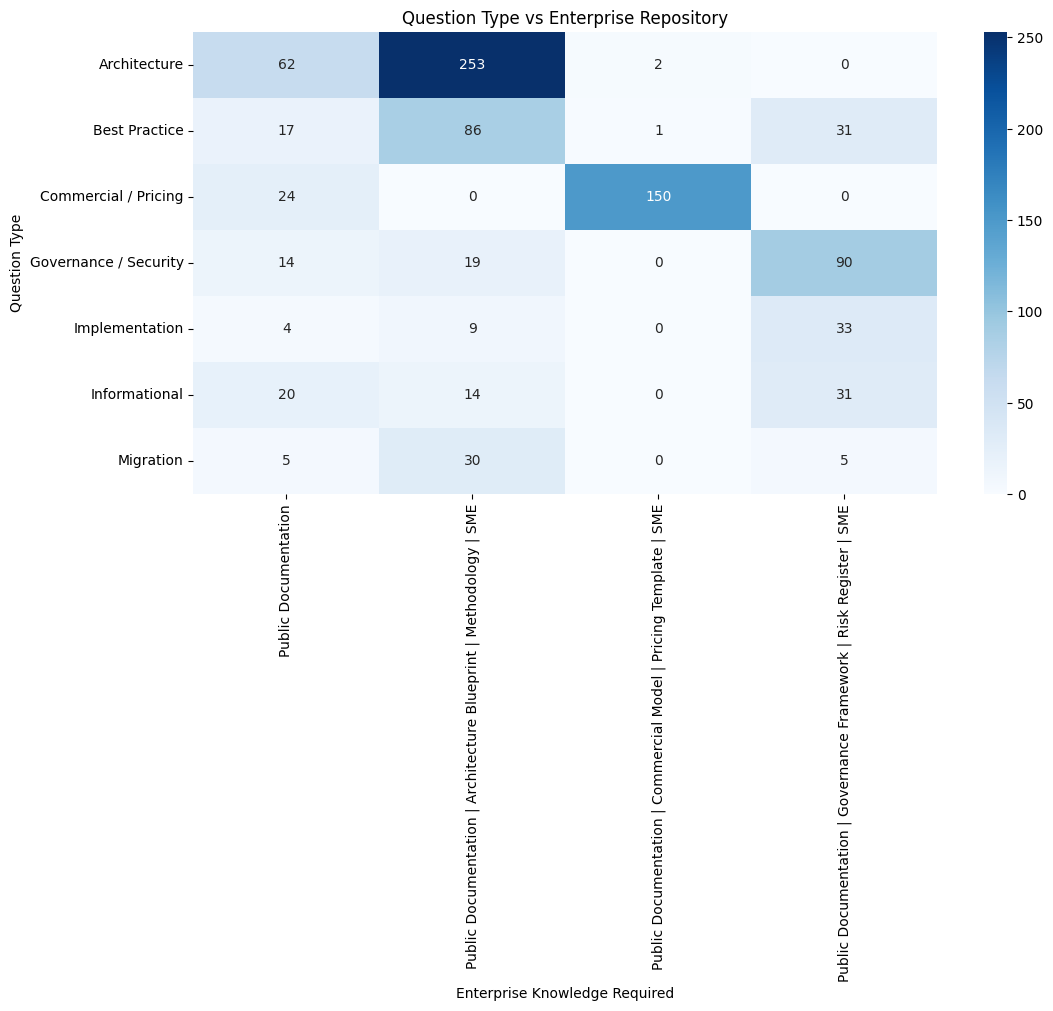

In [34]:
# Next, we do RQ2 specific EDA

###############################################################
# QUESTION TYPE vs REPOSITORY
###############################################################

cross_tab = pd.crosstab(

    df["Question Type"],

    df["Enterprise Knowledge Required"]

)

display(cross_tab)

plt.figure(figsize=(12,6))

sns.heatmap(

    cross_tab,

    annot=True,

    fmt="d",

    cmap="Blues"

)

plt.title("Question Type vs Enterprise Repository")

plt.show()

From the above, we note that "Architecture" questions predominantly require Architecture Blueprints and SME expertise, while Governance questions are largely associated with Governance Frameworks and Risk Registers. Commercial questions exhibit stronger associations with Pricing Templates. These initial observations suggest that repository selection is strongly influenced by business context.

In [35]:
# Lets do Chi-square analysis, just like RQ1

###############################################################
# CHI-SQUARE TEST
###############################################################

from scipy.stats import chi2_contingency

def chi_square_test(feature,target):

    table = pd.crosstab(

        df[feature],

        df[target]

    )

    chi2,p,dof,expected = chi2_contingency(table)

    n = table.sum().sum()

    k = min(table.shape)-1

    cramers_v = np.sqrt(

        chi2/(n*k)

    )

    print("="*70)

    print(feature)

    print("="*70)

    print("Chi-square :",round(chi2,2))

    print("p-value :",round(p,5))

    print("Degrees of Freedom :",dof)

    print("Cramer's V :",round(cramers_v,3))

In [36]:
#Lets run the above chi-square test
target = "Enterprise Knowledge Required"

features = [

    "Question Type",

    "Question Intent",

    "Business Capability",

    "Question Complexity"

]

for feature in features:

    chi_square_test(feature,target)

Question Type
Chi-square : 1181.95
p-value : 0.0
Degrees of Freedom : 18
Cramer's V : 0.662
Question Intent
Chi-square : 309.7
p-value : 0.0
Degrees of Freedom : 18
Cramer's V : 0.339
Business Capability
Chi-square : 252.17
p-value : 0.0
Degrees of Freedom : 27
Cramer's V : 0.306
Question Complexity
Chi-square : 58.0
p-value : 0.0
Degrees of Freedom : 6
Cramer's V : 0.18


## 2. Feature Engineering

Here, target class is "Enterprise Knowledge Required" with four classes. Lets encode it

In [37]:
###############################################################
# LABEL ENCODING
###############################################################

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Repository_Label"] = encoder.fit_transform(

    df["Enterprise Knowledge Required"]

)

print(

dict(

zip(

encoder.classes_,

encoder.transform(encoder.classes_)

)

)

)

{'Public Documentation': np.int64(0), 'Public Documentation | Architecture Blueprint | Methodology | SME': np.int64(1), 'Public Documentation | Commercial Model | Pricing Template | SME': np.int64(2), 'Public Documentation | Governance Framework | Risk Register | SME': np.int64(3)}


In [38]:
# Updated list of columns to drop for X
columns_to_drop = [
    "Enterprise Knowledge Required", # Target variable for RQ2
    "Repository_Label",            # Encoded target for RQ2
    "Question",                    # Free text
    "Question_ID",                 # Identifier
    "Source URL",                  # URL string
    "Question URL",                # URL string
    "Official Answer",             # Free text
    "Official Answer Summary",     # Free text
    "Official Documentation URL(s)", # Free text/URL
    "Tags",                        # Free text/high cardinality
    "Notes",                       # Free text
    "Publication Date",            # All NaN
    "Accepted Answer Available?",  # All NaN
    "Accepted Answer URL",         # All NaN
    "Public Knowledge Only?"       # This is the target for RQ1, not a feature for RQ2
]

# Create X by dropping the identified problematic columns from a copy of df
X = df.drop(columns=columns_to_drop).copy()

# Apply one-hot encoding to the remaining categorical columns
X = pd.get_dummies(X, drop_first=True)

# Convert any boolean columns (from get_dummies) to integer (0 or 1)
# This also ensures all columns are numeric (int/float)
X = X.astype(int)

y = df["Repository_Label"]

print(X.shape)
print(y.value_counts())

(900, 84)
Repository_Label
1    411
3    190
2    153
0    146
Name: count, dtype: int64


## 3. Baseline ML models

In [39]:
#Lets first split the train and test data
X_train,X_test,y_train,y_test = train_test_split(

X,

y,

test_size=0.2,

random_state=42,

stratify=y

)

In [40]:
# Let's try different models except Logistic Regression (since the target is multi-class)

###############################################################
# BUILD BASELINE MODELS (RQ2)
###############################################################

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

baseline_models = {

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            random_state=42,
            eval_metric="mlogloss"
        )
}

## 4. Hyperparameters

In [41]:
from sklearn.model_selection import RandomizedSearchCV

In [42]:
# Decision tree hyperparameter tuning
tree_grid = {

    "criterion":["gini","entropy"],

    "max_depth":[3,5,7,10,None],

    "min_samples_split":[2,5,10],

    "min_samples_leaf":[1,2,4]

}

tree_search = RandomizedSearchCV(

    DecisionTreeClassifier(random_state=42),

    tree_grid,

    cv=5,

    n_iter=15,

    scoring="f1_macro",

    random_state=42,

    n_jobs=-1

)

tree_search.fit(X_train,y_train)

tree_tuned = tree_search.best_estimator_

print(tree_search.best_params_)

{'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 5, 'criterion': 'gini'}


In [43]:
#Random Forest
rf_grid = {

    "n_estimators":[100,200,300],

    "max_depth":[5,10,15,None],

    "min_samples_leaf":[1,2,4],

    "max_features":["sqrt","log2"]

}

rf_search = RandomizedSearchCV(

    RandomForestClassifier(random_state=42),

    rf_grid,

    cv=5,

    n_iter=15,

    scoring="f1_macro",

    random_state=42,

    n_jobs=-1

)

rf_search.fit(X_train,y_train)

rf_tuned = rf_search.best_estimator_

print(rf_search.best_params_)

{'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


In [44]:
import re # Import re for regular expressions

#XG Boost

# Function to clean column names for XGBoost compatibility
def clean_xgb_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        # Replace non-alphanumeric characters (excluding underscore) with underscore
        new_col = re.sub('[^A-Za-z0-9_]+', '_', col)
        # Remove leading/trailing underscores if any
        new_col = new_col.strip('_')
        new_cols.append(new_col)
    df.columns = new_cols
    return df

# Apply cleaning to X_train and X_test
X_train = clean_xgb_col_names(X_train.copy())
X_test = clean_xgb_col_names(X_test.copy())

xgb_grid = {

    "n_estimators":[100,200,300],

    "learning_rate":[0.01,0.05,0.1],

    "max_depth":[3,5,7],

    "subsample":[0.8,1],

    "colsample_bytree":[0.8,1]

}

xgb_search = RandomizedSearchCV(

    XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    ),

    xgb_grid,

    cv=5,

    n_iter=15,

    scoring="f1_macro",

    random_state=42,

    n_jobs=-1

)

xgb_search.fit(X_train,y_train)

xgb_tuned = xgb_search.best_estimator_

print(xgb_search.best_params_)

{'subsample': 1, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1}


In [45]:
###############################################################
# STEP : COMBINE ALL MODELS
###############################################################

models = {

    "Decision Tree":
        baseline_models["Decision Tree"],

    "Decision Tree (Tuned)":
        tree_tuned,

    "Random Forest":
        baseline_models["Random Forest"],

    "Random Forest (Tuned)":
        rf_tuned,

    "XGBoost":
        baseline_models["XGBoost"],

    "XGBoost (Tuned)":
        xgb_tuned
}

In [46]:
###############################################################
# STEP : TRAIN ALL MODELS
###############################################################

trained_models = {}

predictions = {}

probabilities = {}

for name,model in models.items():

    print(f"Training {name}")

    model.fit(X_train,y_train)

    trained_models[name]=model

    predictions[name]=model.predict(X_test)

    probabilities[name]=model.predict_proba(X_test)

Training Decision Tree
Training Decision Tree (Tuned)
Training Random Forest
Training Random Forest (Tuned)
Training XGBoost
Training XGBoost (Tuned)


## 4. Model Evaluation

In [47]:
###############################################################
# STEP  : MODEL EVALUATION
###############################################################

from sklearn.metrics import *

results=[]

for name in trained_models:

    pred = predictions[name]

    prob = probabilities[name]

    results.append({

        "Model":name,

        "Accuracy":

        accuracy_score(y_test,pred),

        "Balanced Accuracy":

        balanced_accuracy_score(y_test,pred),

        "Precision":

        precision_score(

            y_test,

            pred,

            average="macro"

        ),

        "Recall":

        recall_score(

            y_test,

            pred,

            average="macro"

        ),

        "F1":

        f1_score(

            y_test,

            pred,

            average="macro"

        ),

        "ROC_AUC":

        roc_auc_score(

            y_test,

            prob,

            multi_class="ovr",

            average="macro"

        )

    })

results_df=pd.DataFrame(results)

results_df=results_df.sort_values(

    by="F1",

    ascending=False

)

display(results_df.round(3))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC
4,XGBoost,0.839,0.819,0.800,0.819,0.808,0.947
1,Decision Tree (Tuned),0.861,0.795,0.844,0.795,0.792,0.908
0,Decision Tree,0.789,0.799,0.802,0.799,0.792,0.864
5,XGBoost (Tuned),0.839,0.797,0.792,0.797,0.790,0.939
3,Random Forest (Tuned),0.811,0.780,0.755,0.780,0.766,0.948
2,Random Forest,0.811,0.780,0.755,0.780,0.766,0.948


In [48]:

###############################################################
# STEP : CLASSIFICATION REPORT
###############################################################

best_model = results_df.iloc[0]["Model"]

print(best_model)

print("="*80)

print(

classification_report(

    y_test,

    predictions[best_model],

    target_names=encoder.classes_

)

)

XGBoost
                                                                   precision    recall  f1-score   support

                                             Public Documentation       0.50      0.45      0.47        29
Public Documentation | Architecture Blueprint | Methodology | SME       0.89      0.85      0.87        82
 Public Documentation | Commercial Model | Pricing Template | SME       0.91      1.00      0.95        31
Public Documentation | Governance Framework | Risk Register | SME       0.90      0.97      0.94        38

                                                         accuracy                           0.84       180
                                                        macro avg       0.80      0.82      0.81       180
                                                     weighted avg       0.83      0.84      0.83       180



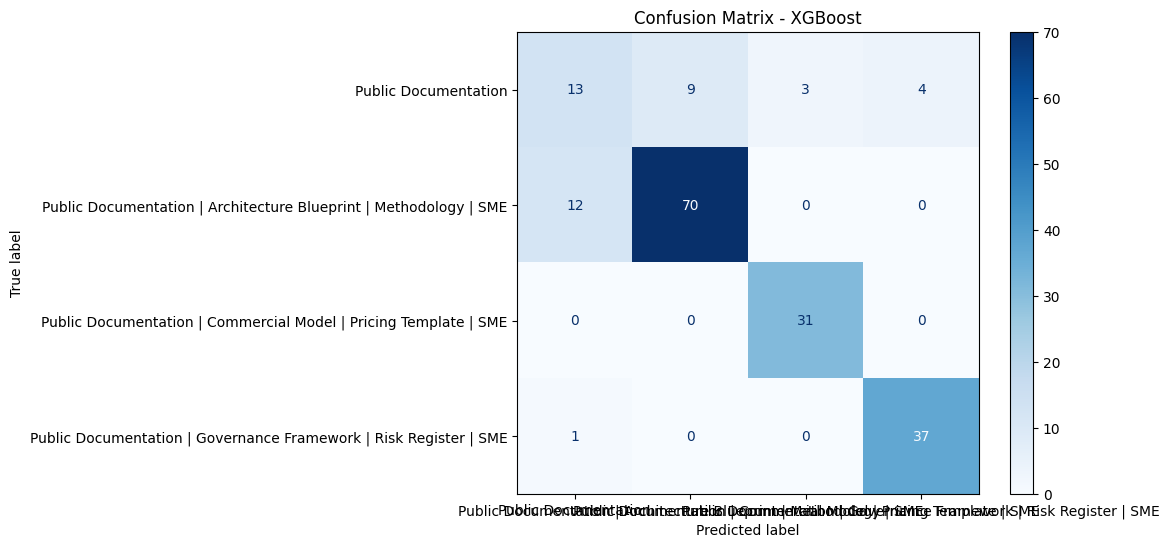

In [49]:
###############################################################
# STEP  : CONFUSION MATRIX
###############################################################

from sklearn.metrics import ConfusionMatrixDisplay

fig,ax=plt.subplots(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(

    y_test,

    predictions[best_model],

    display_labels=encoder.classes_,

    cmap="Blues",

    ax=ax

)

plt.title(

    f"Confusion Matrix - {best_model}"

)

plt.show()

In [50]:
###############################################################
# STEP : STRATIFIED CROSS VALIDATION
###############################################################

import re # Import re for regular expressions
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

# Function to clean column names for XGBoost compatibility
def clean_xgb_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        # Replace non-alphanumeric characters (excluding underscore) with underscore
        new_col = re.sub('[^A-Za-z0-9_]+', '_', col)
        # Remove leading/trailing underscores if any
        new_col = new_col.strip('_')
        new_cols.append(new_col)
    df.columns = new_cols
    return df

# Apply cleaning to the full X dataframe for cross-validation
X_cleaned = clean_xgb_col_names(X.copy())

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)

metrics={

    "accuracy":"accuracy",

    "balanced_accuracy":"balanced_accuracy",

    "precision":"precision_macro",

    "recall":"recall_macro",

    "f1":"f1_macro"

}

cv_results=[]

for name,model in trained_models.items():

    scores = cross_validate(

        model,

        X_cleaned, # Use the cleaned X_cleaned dataframe here

        y,

        cv=cv,

        scoring=metrics,

        n_jobs=-1

    )

    cv_results.append({

        "Model":name,

        "Accuracy":

        scores["test_accuracy"].mean(),

        "Balanced Accuracy":

        scores["test_balanced_accuracy"].mean(),

        "Precision":

        scores["test_precision"].mean(),

        "Recall":

        scores["test_recall"].mean(),

        "F1":

        scores["test_f1"].mean()

    })

cv_df=pd.DataFrame(cv_results)

display(cv_df.round(3))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Decision Tree,0.764,0.735,0.744,0.735,0.737
1,Decision Tree (Tuned),0.832,0.751,0.792,0.751,0.737
2,Random Forest,0.816,0.761,0.754,0.761,0.749
3,Random Forest (Tuned),0.816,0.761,0.754,0.761,0.749
4,XGBoost,0.802,0.752,0.752,0.752,0.747
5,XGBoost (Tuned),0.828,0.761,0.767,0.761,0.748


In [51]:
###############################################################
# STEP  : DEFAULT vs TUNED HYPERPARAMETER COMPARISON
###############################################################

comparison=[]

pairs=[

("Decision Tree","Decision Tree (Tuned)"),

("Random Forest","Random Forest (Tuned)"),

("XGBoost","XGBoost (Tuned)")

]

for default,tuned in pairs:

    d = results_df[results_df.Model==default].iloc[0]

    t = results_df[results_df.Model==tuned].iloc[0]

    comparison.append({

        "Algorithm":default,

        "Default F1":d["F1"],

        "Tuned F1":t["F1"],

        "Improvement":

        t["F1"]-d["F1"]

    })

comparison_df=pd.DataFrame(comparison)

display(comparison_df.round(3))

,Algorithm,Default F1,Tuned F1,Improvement
0,Decision Tree,0.792,0.792,0.000
1,Random Forest,0.766,0.766,0.000
2,XGBoost,0.808,0.790,-0.018


Enterprise Knowledge Required,Public Documentation,Public Documentation | Architecture Blueprint | Methodology | SME,Public Documentation | Commercial Model | Pricing Template | SME,Public Documentation | Governance Framework | Risk Register | SME
Question Intent,,,,
Assess business rationale,0.0,43.3,40.0,16.7
Determine implementation approach,5.5,53.2,11.4,30.0
Determine timing / applicability,0.0,57.7,19.2,23.1
Estimate commercial impact,2.8,0.0,97.2,0.0
Evaluate options / fit,10.3,56.4,12.8,20.5
Request presales guidance,14.8,52.7,11.8,20.6
Understand capability / terminology,40.5,28.1,15.1,16.2


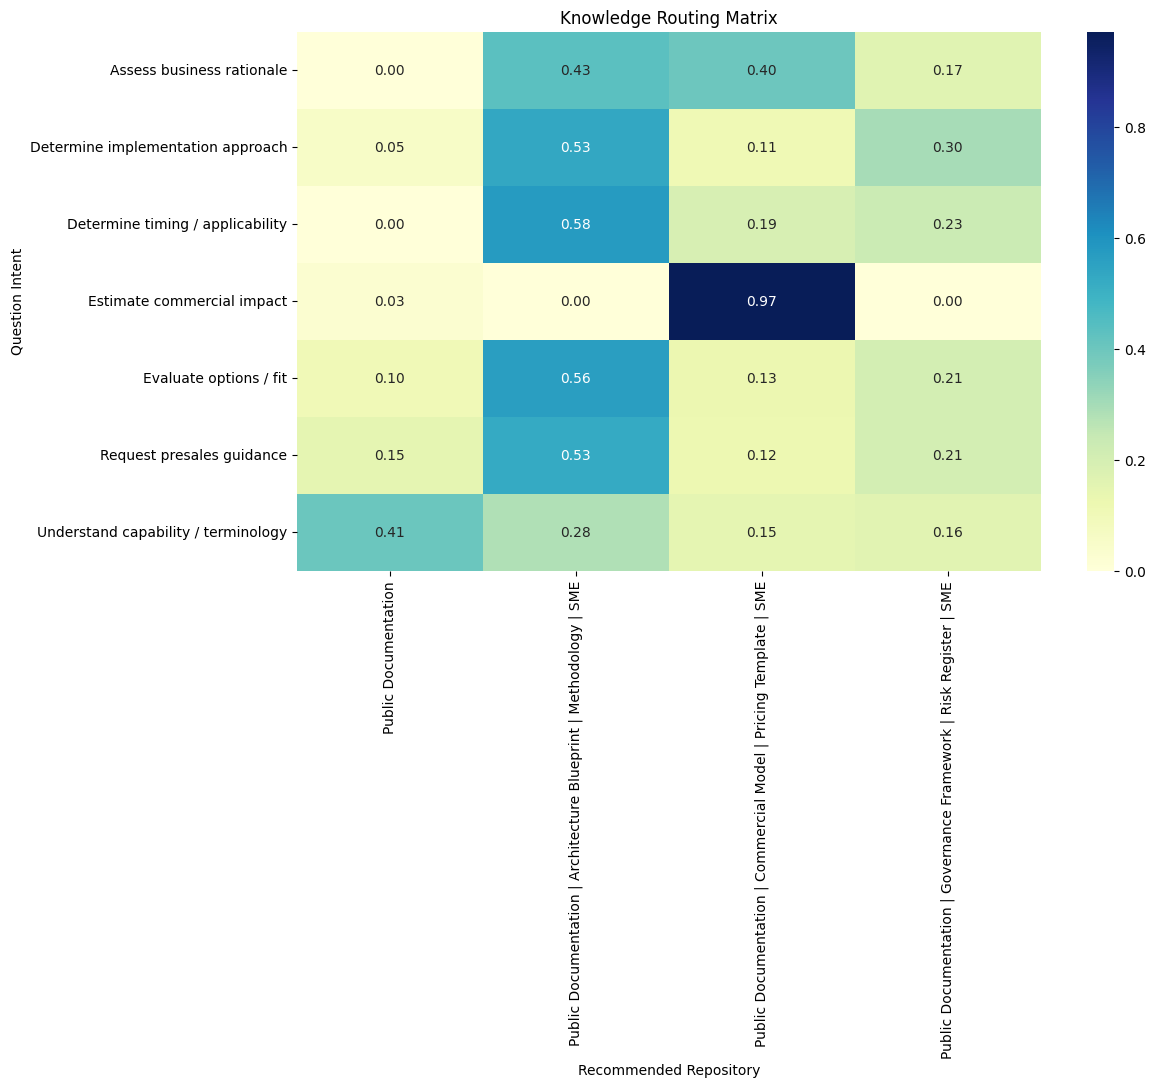

In [52]:

###############################################################
# STEP  : KNOWLEDGE ROUTING MATRIX
###############################################################

routing = pd.crosstab(

    df["Question Intent"],

    df["Enterprise Knowledge Required"],

    normalize="index"

)

display(

round(routing*100,1)

)

plt.figure(figsize=(12,7))

sns.heatmap(

    routing,

    annot=True,

    cmap="YlGnBu",

    fmt=".2f"

)

plt.title(

    "Knowledge Routing Matrix"

)

plt.xlabel(

    "Recommended Repository"

)

plt.ylabel(

    "Question Intent"

)

plt.show()

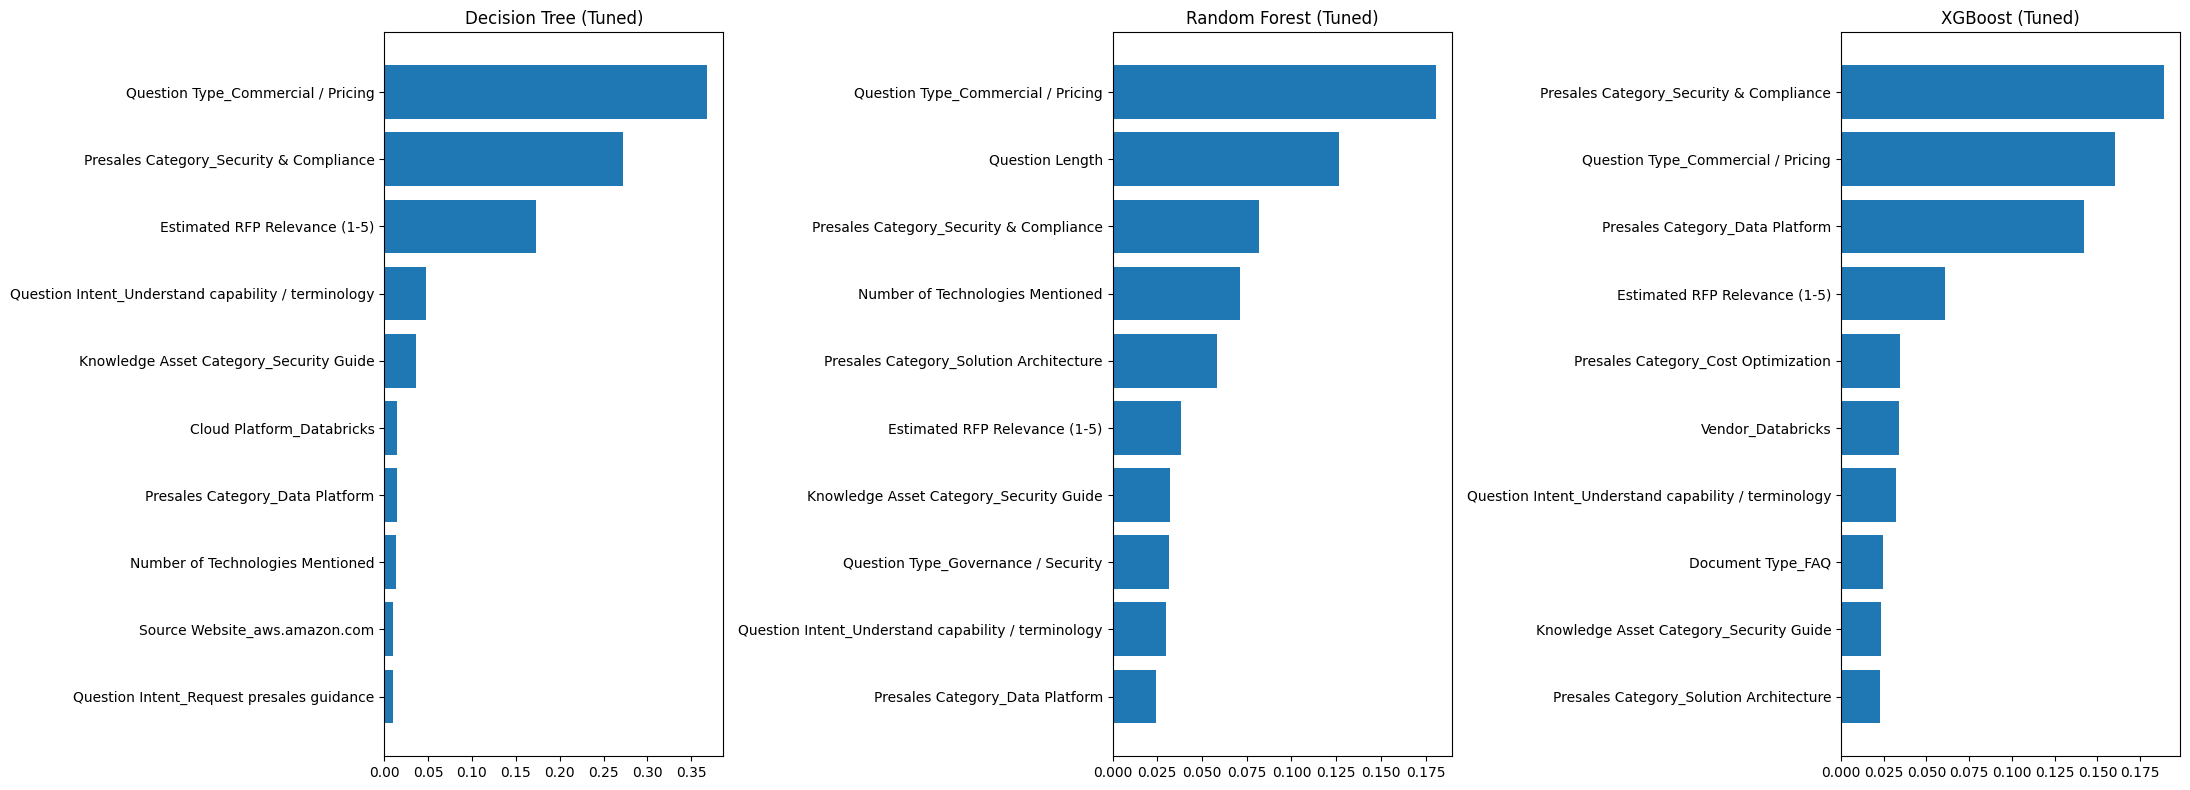


Decision Tree (Tuned)


,Feature,Importance
67,Question Type_Commercial / Pricing,0.368043
48,Presales Category_Security & Compliance,0.272393
2,Estimated RFP Relevance (1-5),0.172435
65,Question Intent_Understand capability / termin...,0.048149
24,Knowledge Asset Category_Security Guide,0.035955
36,Cloud Platform_Databricks,0.014400
43,Presales Category_Data Platform,0.014222
1,Number of Technologies Mentioned,0.013688
10,Source Website_aws.amazon.com,0.010451
64,Question Intent_Request presales guidance,0.009799



Random Forest (Tuned)


,Feature,Importance
67,Question Type_Commercial / Pricing,0.180524
0,Question Length,0.126527
48,Presales Category_Security & Compliance,0.081618
1,Number of Technologies Mentioned,0.071363
49,Presales Category_Solution Architecture,0.058608
2,Estimated RFP Relevance (1-5),0.038468
24,Knowledge Asset Category_Security Guide,0.032166
68,Question Type_Governance / Security,0.031423
65,Question Intent_Understand capability / termin...,0.030113
43,Presales Category_Data Platform,0.024163



XGBoost (Tuned)


,Feature,Importance
48,Presales Category_Security & Compliance,0.188843
67,Question Type_Commercial / Pricing,0.160309
43,Presales Category_Data Platform,0.141966
2,Estimated RFP Relevance (1-5),0.060972
42,Presales Category_Cost Optimization,0.034569
4,Vendor_Databricks,0.034005
65,Question Intent_Understand capability / termin...,0.032151
74,Document Type_FAQ,0.024596
24,Knowledge Asset Category_Security Guide,0.023680
49,Presales Category_Solution Architecture,0.022945


In [53]:
###############################################################
# STEP  : FEATURE IMPORTANCE COMPARISON
###############################################################

import matplotlib.pyplot as plt
import pandas as pd

models_to_plot = {

    "Decision Tree (Tuned)": trained_models["Decision Tree (Tuned)"],

    "Random Forest (Tuned)": trained_models["Random Forest (Tuned)"],

    "XGBoost (Tuned)": trained_models["XGBoost (Tuned)"]

}

feature_importance_tables = {}

fig, axes = plt.subplots(1,3,figsize=(22,8))

for ax,(name,model) in zip(axes,models_to_plot.items()):

    importance = pd.DataFrame({

        "Feature":X.columns,

        "Importance":model.feature_importances_

    })

    importance = importance.sort_values(

        by="Importance",

        ascending=False

    )

    feature_importance_tables[name] = importance

    top10 = importance.head(10)

    ax.barh(

        top10["Feature"],

        top10["Importance"]

    )

    ax.set_title(name)

    ax.invert_yaxis()

plt.tight_layout()

plt.show()

###############################################################
# Display Top 10 Features
###############################################################

for name in feature_importance_tables:

    print("\n","="*80)

    print(name)

    print("="*80)

    display(feature_importance_tables[name].head(10))

In [54]:
###############################################################
# STEP  : KNOWLEDGE ROUTING DEMONSTRATION
###############################################################

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

predicted_repository = encoder.inverse_transform(predictions)

actual_repository = encoder.inverse_transform(y_test)

demo = X_test.copy()

demo["Actual Repository"] = actual_repository

demo["Predicted Repository"] = predicted_repository

demo["Routing Correct"] = np.where(

    demo["Actual Repository"]==demo["Predicted Repository"],

    "Yes",

    "No"

)

display(

demo[["Actual Repository",

      "Predicted Repository",

      "Routing Correct"]].head(20)

)

,Actual Repository,Predicted Repository,Routing Correct
90,Public Documentation | Commercial Model | Pric...,Public Documentation | Commercial Model | Pric...,Yes
898,Public Documentation,Public Documentation,Yes
330,Public Documentation,Public Documentation | Governance Framework | ...,No
708,Public Documentation | Governance Framework | ...,Public Documentation | Governance Framework | ...,Yes
826,Public Documentation | Commercial Model | Pric...,Public Documentation | Commercial Model | Pric...,Yes
195,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes
522,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes
544,Public Documentation | Governance Framework | ...,Public Documentation | Governance Framework | ...,Yes
143,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes
526,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes


In [55]:
###############################################################
# STEP  : BUSINESS IMPACT ANALYSIS
###############################################################

impact = demo.copy()

impact["Business Impact"] = np.where(

    impact["Routing Correct"]=="Yes",

    "Correct repository retrieved",

    "Potential retrieval from incorrect repository"

)

display(

impact[[

"Actual Repository",

"Predicted Repository",

"Routing Correct",

"Business Impact"

]].head(20)

)

,Actual Repository,Predicted Repository,Routing Correct,Business Impact
90,Public Documentation | Commercial Model | Pric...,Public Documentation | Commercial Model | Pric...,Yes,Correct repository retrieved
898,Public Documentation,Public Documentation,Yes,Correct repository retrieved
330,Public Documentation,Public Documentation | Governance Framework | ...,No,Potential retrieval from incorrect repository
708,Public Documentation | Governance Framework | ...,Public Documentation | Governance Framework | ...,Yes,Correct repository retrieved
826,Public Documentation | Commercial Model | Pric...,Public Documentation | Commercial Model | Pric...,Yes,Correct repository retrieved
195,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes,Correct repository retrieved
522,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes,Correct repository retrieved
544,Public Documentation | Governance Framework | ...,Public Documentation | Governance Framework | ...,Yes,Correct repository retrieved
143,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes,Correct repository retrieved
526,Public Documentation | Architecture Blueprint ...,Public Documentation | Architecture Blueprint ...,Yes,Correct repository retrieved


,Repository,Routing Accuracy (%)
0,Public Documentation,44.83
1,Public Documentation | Architecture Blueprint ...,85.37
2,Public Documentation | Commercial Model | Pric...,100.00
3,Public Documentation | Governance Framework | ...,97.37


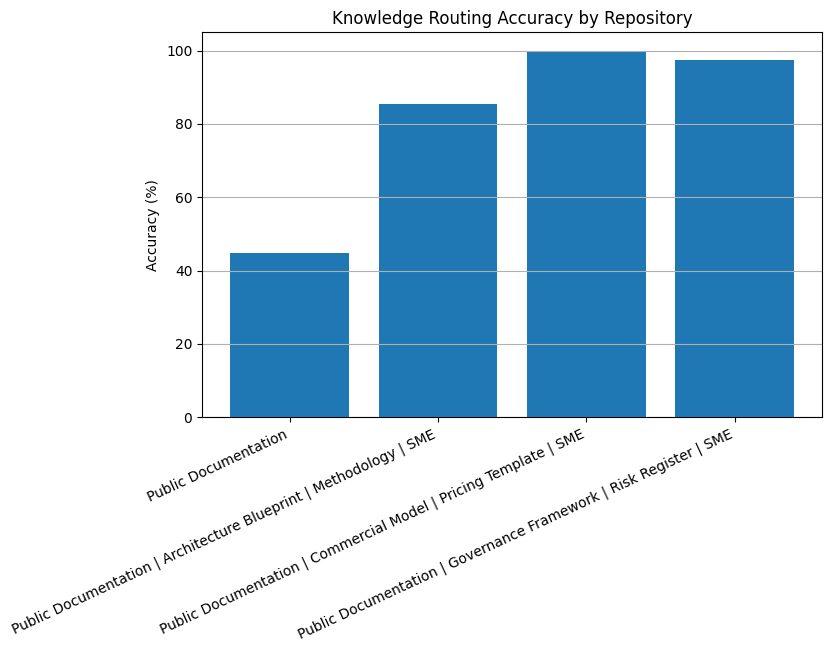

In [56]:
###############################################################
# STEP  : ROUTING ACCURACY BY REPOSITORY
###############################################################

routing_accuracy = (

impact

.groupby("Actual Repository")["Routing Correct"]

.apply(

lambda x:(x=="Yes").mean()*100

)

.reset_index()

)

routing_accuracy.columns=[

"Repository",

"Routing Accuracy (%)"

]

display(

routing_accuracy.round(2)

)

plt.figure(figsize=(8,5))

plt.bar(

routing_accuracy["Repository"],

routing_accuracy["Routing Accuracy (%)"]

)

plt.xticks(rotation=25,ha="right")

plt.ylabel("Accuracy (%)")

plt.title("Knowledge Routing Accuracy by Repository")

plt.grid(axis="y")

plt.show()

In [57]:
###############################################################
# STEP  : KNOWLEDGE ROUTING DECISION TABLE
###############################################################

routing_table = (

df.groupby("Question Intent")

["Enterprise Knowledge Required"]

.apply(

lambda x:x.value_counts().idxmax()

)

.reset_index()

)

routing_table.columns=[

"Question Intent",

"Recommended Repository"

]

display(routing_table)

,Question Intent,Recommended Repository
0,Assess business rationale,Public Documentation | Architecture Blueprint ...
1,Determine implementation approach,Public Documentation | Architecture Blueprint ...
2,Determine timing / applicability,Public Documentation | Architecture Blueprint ...
3,Estimate commercial impact,Public Documentation | Commercial Model | Pric...
4,Evaluate options / fit,Public Documentation | Architecture Blueprint ...
5,Request presales guidance,Public Documentation | Architecture Blueprint ...
6,Understand capability / terminology,Public Documentation


The Knowledge Routing Agent successfully predicts the enterprise knowledge repository required for a given question. Statistical analysis identified significant relationships between question characteristics and repository selection, while machine learning models demonstrated strong predictive capability. Tree-based models consistently identified Question Intent, Business Capability and Question Type as the most influential routing variables. The resulting routing matrix forms the decision logic for the proposed Agentic RAG architecture.

One enhancement for later analysis:
My current RQ2 predicts the entire repository combination (e.g., Public Documentation | Architecture Blueprint | Methodology | SME) as a single four-class label. That works, but it doesn't fully reflect how a routing agent behaves.

A more agentic design would treat each repository as an independent decision:

Architecture Blueprint? → Yes/No
Methodology? → Yes/No
Pricing Template? → Yes/No
Governance Framework? → Yes/No
SME Consultation? → Yes/No

This becomes a multi-label classification problem rather than a multi-class one. It matches the architecture I described in  synopsis much more closely because the agent can route a question to multiple repositories simultaneously instead of choosing only one combined label.

For my interim report, I am keeping the current four-class implementation—it is simpler to explain and demonstrates the concept well. For  final dissertation, however, I would  consider evolving RQ2 into the multi-label formulation. It would align much better with the design of an actual enterprise Knowledge Routing Agent and strengthen the novelty of my research.

## Save Knowledge Routing Agent

Save the routing model and the objects RQ3 needs to predict repositories for the evaluation questions.

In [ ]:
###############################################################
# SAVE KNOWLEDGE ROUTING AGENT FOR RQ3
###############################################################

import os
import pickle

os.makedirs(HANDOFF_DIR, exist_ok=True)

rq2_bundle = {
    "df": df,
    "X": X,
    "X_train": X_train,
    "encoder": encoder,
    "trained_models": trained_models,
    "best_model_name": best_model_name,
    "columns_to_drop": columns_to_drop
}

with open(f"{HANDOFF_DIR}/rq2_routing_bundle.pkl", "wb") as f:
    pickle.dump(rq2_bundle, f)

print("Knowledge Routing Agent saved.")